# Наивный байесовский классификатор: угадываем рубрику новости по заголовку

Команда 15. Данные: новости Lenta.ru (Kaggle), 1999–2019.

1. Смотрим на данные
2. Пишем наивный Байес с нуля и сверяем со sklearn
3. Считаем маленький пример руками
4. Сравниваем с другими моделями
5. Смотрим, что модель выучила

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

RAW_CANDIDATES = [Path("data/lenta-ru-news.csv"),
                  Path("data/lenta-ru-news.csv.bz2"),
                  Path("data/lenta-ru-news.csv.zip")]
DATA_PATH = Path("data/lenta_titles.csv")

plt.rcParams.update({"figure.dpi": 120,
                     "axes.spines.top": False,
                     "axes.spines.right": False})

In [2]:
if not DATA_PATH.exists():
    raw_path = next((p for p in RAW_CANDIDATES if p.exists()), None)
    if raw_path is None:
        raise FileNotFoundError(
            "Скачайте lenta-ru-news.csv: "
            "https://www.kaggle.com/datasets/yutkin/corpus-of-russian-news-articles-from-lenta "
            "и положите в src/data/"
        )
    keep = {"title", "topic", "date"}
    chunks = pd.read_csv(raw_path, usecols=lambda c: c in keep,
                         chunksize=100_000, low_memory=False)
    pd.concat(chunks, ignore_index=True).to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH, dtype=str)
print(raw.shape)
print(raw.columns.tolist())
raw.head()

(800975, 3)
['title', 'topic', 'date']


,title,topic,date
0,1914. Русские войска вступили в пределы Венгрии,Библиотека,1914/09/16
1,1914. Празднование столетия М.Ю. Лермонтова от...,Библиотека,1914/09/16
2,1914. Das ist Nesteroff!,Библиотека,1914/09/17
3,1914. Бульдог-гонец под Льежем,Библиотека,1914/09/17
4,1914. Под Люблином пойман швабский зверь,Библиотека,1914/09/18


In [3]:
print("Пропуски:", raw.isna().sum().to_dict())
raw["topic"].value_counts()

Пропуски: {'title': 0, 'topic': 62002, 'date': 0}


topic
Россия               160445
Мир                  136621
Экономика             79528
Спорт                 64413
Культура              53797
Бывший СССР           53402
Наука и техника       53136
Интернет и СМИ        44663
Из жизни              27605
Дом                   21734
Силовые структуры     19596
Ценности               7766
Бизнес                 7399
Путешествия            6408
69-я параллель         1268
Крым                    666
Культпросвет            340
Легпром                 114
Библиотека               65
Оружие                    3
ЧМ-2014                   2
Сочи                      1
МедНовости                1
Name: count, dtype: int64

In [4]:
raw["year"] = pd.to_datetime(raw["date"], errors="coerce").dt.year
pd.set_option("display.max_columns", 30)
pd.crosstab(raw["topic"], raw["year"]).loc[:, 2008:]

year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
topic,,,,,,,,,,,
69-я параллель,0,0,0,0,0,0,0,0,451,474,343
Библиотека,0,0,0,0,0,0,54,6,0,0,0
Бизнес,0,0,0,0,0,0,145,2407,2831,2014,2
Бывший СССР,3829,3946,3754,3057,3490,3409,5784,4169,5063,4065,2804
Дом,2197,1922,1783,2279,2029,1384,1204,1205,2114,1742,1669
Из жизни,1780,1697,1718,1677,1352,1882,1759,1750,2000,1976,2947
Интернет и СМИ,2697,3137,2679,3126,3272,2776,1906,1977,4000,3667,3294
Крым,0,0,0,0,0,0,0,0,5,573,88
Культпросвет,0,0,0,0,0,0,0,0,33,277,30


## Какие данные берем

Рубрики на Lenta.ru менялись: «Путешествия» появились только в 2015 году, «Силовые структуры» — в 2013-м.
Поэтому берём 2015–2018 годы и 8 рубрик, по 5000 заголовков из каждой.

In [5]:
TOPICS = ["Спорт", "Экономика", "Культура", "Наука и техника",
          "Интернет и СМИ", "Путешествия", "Силовые структуры", "Мир"]
YEARS = range(2015, 2019)
PER_TOPIC = 5000

df = raw[raw["topic"].isin(TOPICS) & raw["year"].isin(YEARS)].copy()
df["title"] = df["title"].str.replace("\xa0", " ").str.strip()
df = df.drop_duplicates("title")

df = (df.groupby("topic", group_keys=False)
        .sample(n=PER_TOPIC, random_state=SEED)
        .reset_index(drop=True)[["title", "topic", "year"]])

print(df.shape)
df["topic"].value_counts()

(40000, 3)


topic
Интернет и СМИ       5000
Культура             5000
Мир                  5000
Наука и техника      5000
Путешествия          5000
Силовые структуры    5000
Спорт                5000
Экономика            5000
Name: count, dtype: int64

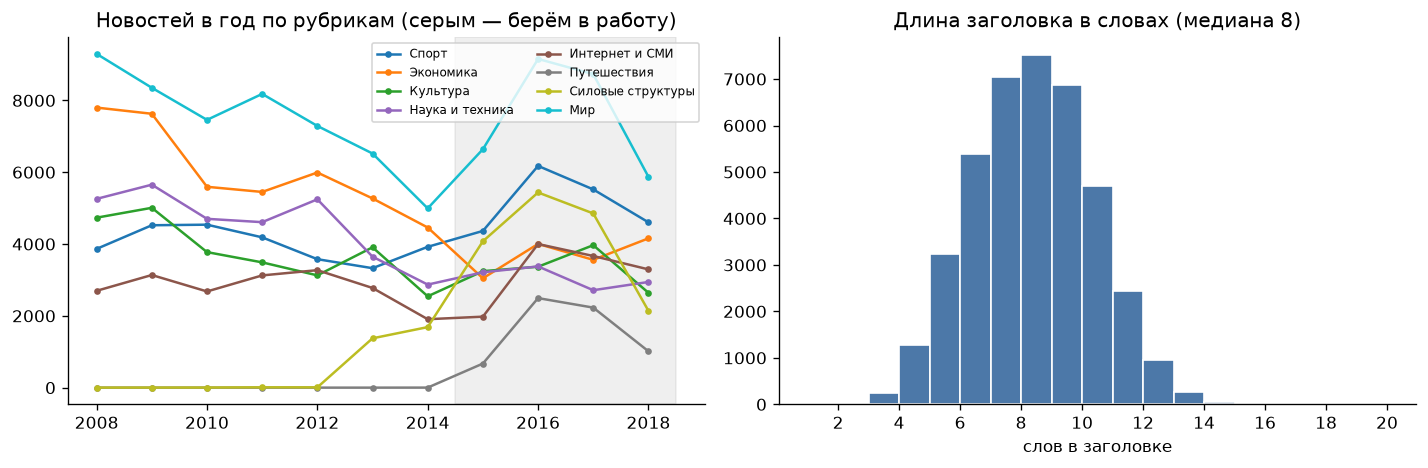

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

by_year = pd.crosstab(raw["year"], raw["topic"]).loc[2008:2018, TOPICS]
by_year.plot(ax=axes[0], marker="o", ms=3, lw=1.5, cmap="tab10")
axes[0].axvspan(2014.5, 2018.5, color="grey", alpha=0.12)
axes[0].set_title("Новостей в год по рубрикам (серым — берём в работу)")
axes[0].set_xlabel("")
axes[0].legend(fontsize=7, ncol=2)

df["n_words"] = df["title"].str.split().str.len()
axes[1].hist(df["n_words"], bins=range(1, 21), color="#4C78A8", edgecolor="white")
axes[1].set_title(f"Длина заголовка в словах (медиана {df['n_words'].median():.0f})")
axes[1].set_xticks(range(2, 21, 2))
axes[1].set_xlabel("слов в заголовке")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_data.png", bbox_inches="tight")
plt.show()

In [7]:
pd.set_option("display.max_colwidth", 120)
df.groupby("topic").sample(2, random_state=SEED)[["topic", "title"]]

,topic,title
1501,Интернет и СМИ,Эксперт призвал контролировать Telegram для борьбы с терроризмом и наркоманией
2586,Интернет и СМИ,Анонсирован запуск машины для поиска сохраненного порно
6078,Культура,Warner Bros. переснимет первую «Матрицу»
7889,Культура,Фильм про Довлатова получил приз независимого жюри Берлинале
11105,Мир,Мужчина перерезал горло бывшей жене в торговом центре в Мексике
11176,Мир,В США предложили убрать с банкнот фразу In God We Trust
17077,Наука и техника,Представлена программа мероприятий Года науки Великобритании и России
18032,Наука и техника,НАСА опубликовало снимок центра Млечного Пути
23902,Путешествия,Самолет экстренно посадили из-за невыносимого запаха
24338,Путешествия,Путин обозначил условия возобновления полетов в Египет
